In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
apr=pd.read_csv(r"C:\Users\shrus\Downloads\archive (13)\Amazon Product Reviews.csv")

In [3]:
apr.shape

(1597, 27)

In [4]:
apr.head()

,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight
0,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I initially had trouble deciding between the p...,"Paperwhite voyage, no regrets!",NaN,NaN,Cristina M,NaN,NaN,205 grams
1,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,Allow me to preface this with a little history...,One Simply Could Not Ask For More,NaN,NaN,Ricky,NaN,NaN,205 grams
2,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,4.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I am enjoying it so far. Great for reading. Ha...,Great for those that just want an e-reader,NaN,NaN,Tedd Gardiner,NaN,NaN,205 grams
3,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I bought one of the first Paperwhites and have...,Love / Hate relationship,NaN,NaN,Dougal,NaN,NaN,205 grams
4,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I have to say upfront - I don't like coroporat...,I LOVE IT,NaN,NaN,Miljan David Tanic,NaN,NaN,205 grams


In [5]:
apr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1597 entries, 0 to 1596
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1597 non-null   object 
 1   asins                 1597 non-null   object 
 2   brand                 1597 non-null   object 
 3   categories            1597 non-null   object 
 4   colors                774 non-null    object 
 5   dateAdded             1597 non-null   object 
 6   dateUpdated           1597 non-null   object 
 7   dimension             565 non-null    object 
 8   ean                   898 non-null    float64
 9   keys                  1597 non-null   object 
 10  manufacturer          965 non-null    object 
 11  manufacturerNumber    902 non-null    object 
 12  name                  1597 non-null   object 
 13  prices                1597 non-null   object 
 14  reviews.date          1217 non-null   object 
 15  reviews.doRecommend  

In [7]:
apr.describe()

,ean,reviews.numHelpful,reviews.rating,reviews.userCity,reviews.userProvince,sizes,upc
count,8.980000e+02,900.000000,1177.000000,0.0,0.0,0.0,8.980000e+02
mean,8.443135e+11,83.584444,4.359388,NaN,NaN,NaN,8.443135e+11
std,3.416444e+09,197.150238,1.021445,NaN,NaN,NaN,3.416444e+09
min,8.416670e+11,0.000000,1.000000,NaN,NaN,NaN,8.416670e+11
25%,8.416670e+11,0.000000,4.000000,NaN,NaN,NaN,8.416670e+11
50%,8.416670e+11,0.000000,5.000000,NaN,NaN,NaN,8.416670e+11
75%,8.487190e+11,34.000000,5.000000,NaN,NaN,NaN,8.487190e+11
max,8.487190e+11,997.000000,5.000000,NaN,NaN,NaN,8.487190e+11


In [8]:
apr.isnull().sum()[apr.isnull().sum()>0]

colors                   823
dimension               1032
ean                      699
manufacturer             632
manufacturerNumber       695
reviews.date             380
reviews.doRecommend     1058
reviews.numHelpful       697
reviews.rating           420
reviews.title             17
reviews.userCity        1597
reviews.userProvince    1597
reviews.username          17
sizes                   1597
upc                      699
weight                   911
dtype: int64

In [9]:
sentiment_df = apr[['reviews.text', 'reviews.rating']].copy()

In [10]:
sentiment_df.head()

,reviews.text,reviews.rating
0,I initially had trouble deciding between the p...,5.0
1,Allow me to preface this with a little history...,5.0
2,I am enjoying it so far. Great for reading. Ha...,4.0
3,I bought one of the first Paperwhites and have...,5.0
4,I have to say upfront - I don't like coroporat...,5.0


In [11]:
sentiment_df = sentiment_df.dropna(subset=['reviews.rating'])

In [12]:
sentiment_df.shape

(1177, 2)

In [17]:
def get_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

sentiment_df.Sentiment = sentiment_df['reviews.rating'].apply(get_sentiment)

In [18]:
sentiment_df.head(10)

,reviews.text,reviews.rating,Sentiment
0,I initially had trouble deciding between the p...,5.0,Positive
1,Allow me to preface this with a little history...,5.0,Positive
2,I am enjoying it so far. Great for reading. Ha...,4.0,Positive
3,I bought one of the first Paperwhites and have...,5.0,Positive
4,I have to say upfront - I don't like coroporat...,5.0,Positive
13,"Had older model, that you could text to speech...",4.0,Positive
14,This is a review of the Kindle Paperwhite laun...,5.0,Positive
15,I love my kindle! I got one for my fiance on h...,5.0,Positive
16,"Vraiment bon petit appareil , lger et facile d...",4.0,Positive
17,Exactly what it is supposed to be. Works great...,5.0,Positive


In [19]:
sentiment_df.Sentiment.value_counts()

Sentiment
Positive    977
Neutral     124
Negative     76
Name: count, dtype: int64

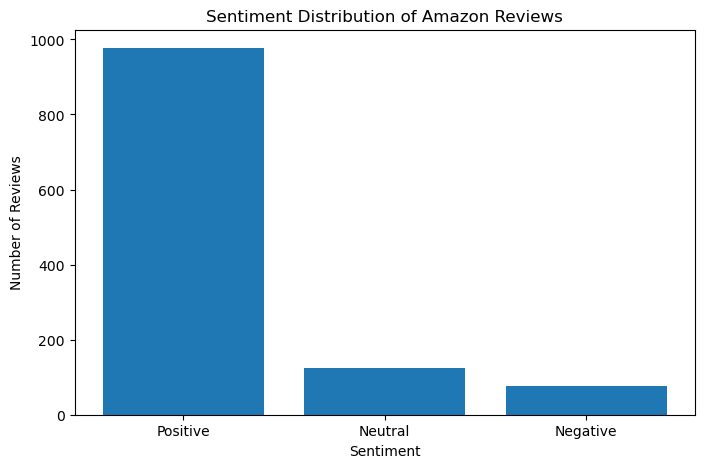

In [20]:
sentiment_counts = sentiment_df.Sentiment.value_counts()

plt.figure(figsize=(8, 5))

plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title('Sentiment Distribution of Amazon Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

In [21]:
## Sentiment Distribution

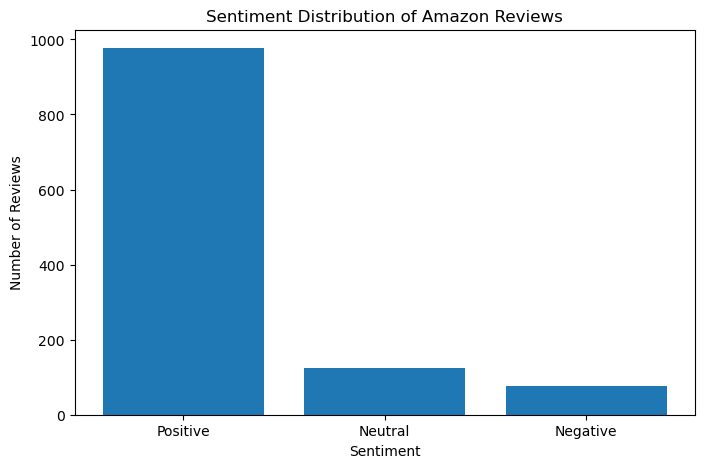

In [22]:
sentiment_counts = sentiment_df.Sentiment.value_counts()

plt.figure(figsize=(8, 5))

plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title('Sentiment Distribution of Amazon Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

In [23]:
sentiment_percent = sentiment_df['Sentiment'].value_counts(normalize=True) * 100

print(sentiment_percent.round(2))

Sentiment
Positive    83.01
Neutral     10.54
Negative     6.46
Name: proportion, dtype: float64


In [25]:
#The sentiment distribution shows that the dataset is highly imbalanced.
#Positive reviews form the majority of the dataset, while neutral and negative
#reviews are comparatively fewer. Therefore, accuracy alone may not be sufficient
#to evaluate the classification models. Precision, recall, and F1-score will also
#be considered.

In [28]:
sentiment_df[['reviews.text', 'Sentiment']].head(10)

,reviews.text,Sentiment
0,I initially had trouble deciding between the p...,Positive
1,Allow me to preface this with a little history...,Positive
2,I am enjoying it so far. Great for reading. Ha...,Positive
3,I bought one of the first Paperwhites and have...,Positive
4,I have to say upfront - I don't like coroporat...,Positive
13,"Had older model, that you could text to speech...",Positive
14,This is a review of the Kindle Paperwhite laun...,Positive
15,I love my kindle! I got one for my fiance on h...,Positive
16,"Vraiment bon petit appareil , lger et facile d...",Positive
17,Exactly what it is supposed to be. Works great...,Positive


In [27]:
sentiment_df['reviews.text'].str.len().describe()

count     1177.000000
mean       735.956669
std       1284.391365
min          3.000000
25%        115.000000
50%        280.000000
75%       1527.000000
max      19739.000000
Name: reviews.text, dtype: float64

In [29]:
sentiment_df['reviews.text'].isnull().sum()

np.int64(0)

In [35]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import re

In [32]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [36]:
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove punctuation and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Tokenization
    tokens = word_tokenize(text)
    
    # Remove stopwords and lemmatize
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    
    # Join tokens back into a sentence
    return ' '.join(tokens)

In [37]:
sample_text = sentiment_df['reviews.text'].iloc[0]

print("Original:")
print(sample_text)

print("\nCleaned:")
print(preprocess_text(sample_text))

Original:
I initially had trouble deciding between the paperwhite and the voyage because reviews more or less said the same thing: the paperwhite is great, but if you have spending money, go for the voyage.Fortunately, I had friends who owned each, so I ended up buying the paperwhite on this basis: both models now have 300 ppi, so the 80 dollar jump turns out pricey the voyage's page press isn't always sensitive, and if you are fine with a specific setting, you don't need auto light adjustment).It's been a week and I am loving my paperwhite, no regrets! The touch screen is receptive and easy to use, and I keep the light at a specific setting regardless of the time of day. (In any case, it's not hard to change the setting either, as you'll only be changing the light level at a certain time of day, not every now and then while reading).Also glad that I went for the international shipping option with Amazon. Extra expense, but delivery was on time, with tracking, and I didnt need to worry

In [38]:
sentiment_df['cleaned_text'] = sentiment_df['reviews.text'].apply(preprocess_text)

In [39]:
sentiment_df[['reviews.text', 'cleaned_text']].head(10)

,reviews.text,cleaned_text
0,I initially had trouble deciding between the p...,initially trouble deciding paperwhite voyage r...
1,Allow me to preface this with a little history...,allow preface little history casual reader own...
2,I am enjoying it so far. Great for reading. Ha...,enjoying far great reading original fire since...
3,I bought one of the first Paperwhites and have...,bought one first paperwhites pleased constant ...
4,I have to say upfront - I don't like coroporat...,say upfront dont like coroporate hermetically ...
13,"Had older model, that you could text to speech...",older model could text speech one hasnt liked ...
14,This is a review of the Kindle Paperwhite laun...,review kindle paperwhite launched july essenti...
15,I love my kindle! I got one for my fiance on h...,love kindle got one fiance birthday loved deci...
16,"Vraiment bon petit appareil , lger et facile d...",vraiment bon petit appareil lger et facile emp...
17,Exactly what it is supposed to be. Works great...,exactly supposed work great love builtin light...


In [40]:
sentiment_df['cleaned_text'].isnull().sum()

np.int64(0)

In [42]:
sentiment_df = sentiment_df[sentiment_df['cleaned_text'].str.strip() != '']

In [43]:
(sentiment_df['cleaned_text'].str.strip() == '').sum()

np.int64(0)

In [44]:
sentiment_df.shape

(1176, 4)

In [45]:
### TF-IDF Vectorization

#TF-IDF stands for Term Frequency-Inverse Document Frequency.

#It converts text into numerical values that machine learning models can understand.

#TF-IDF gives higher importance to words that are frequent in a particular
#document but less common across the entire collection of documents.

#It consists of two main components:

#1. Term Frequency (TF) – measures how frequently a word appears in a document.
#2. Inverse Document Frequency (IDF) – reduces the importance of words that
 #  appear in many documents.

#Therefore, TF-IDF helps identify words that are more informative for
#classifying sentiment.

In [46]:
X = sentiment_df['cleaned_text']
y = sentiment_df['Sentiment']

In [47]:
print(X.shape)
print(y.shape)

(1176,)
(1176,)


In [49]:
from sklearn.model_selection import train_test_split

In [50]:
print(train_test_split)

<function train_test_split at 0x0000013C790237E0>


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [52]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 940
Testing samples: 236


In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [54]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [55]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [56]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [57]:
X_test_tfidf = tfidf.transform(X_test)

In [58]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (940, 5000)
Testing TF-IDF shape: (236, 5000)


In [59]:
from sklearn.naive_bayes import MultinomialNB

In [60]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [61]:
y_pred_nb = nb_model.predict(X_test_tfidf)

In [62]:
print("Actual:", y_test.values[:10])
print("Predicted:", y_pred_nb[:10])

Actual: ['Positive' 'Positive' 'Positive' 'Neutral' 'Negative' 'Negative'
 'Neutral' 'Positive' 'Positive' 'Positive']
Predicted: ['Positive' 'Positive' 'Positive' 'Neutral' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive']


In [64]:
from sklearn.metrics import *

In [65]:
accuracy_nb = accuracy_score(y_test, y_pred_nb)

precision_nb = precision_score(
    y_test,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

recall_nb = recall_score(
    y_test,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

f1_nb = f1_score(
    y_test,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

print("Naive Bayes Results")
print("--------------------")
print("Accuracy :", accuracy_nb)
print("Precision:", precision_nb)
print("Recall   :", recall_nb)
print("F1 Score :", f1_nb)

Naive Bayes Results
--------------------
Accuracy : 0.8771186440677966
Precision: 0.8293973634651601
Recall   : 0.8771186440677966
F1 Score : 0.838036398853058


In [66]:
print(classification_report(
    y_test,
    y_pred_nb,
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        15
     Neutral       1.00      0.44      0.61        25
    Positive       0.87      1.00      0.93       196

    accuracy                           0.88       236
   macro avg       0.62      0.48      0.51       236
weighted avg       0.83      0.88      0.84       236



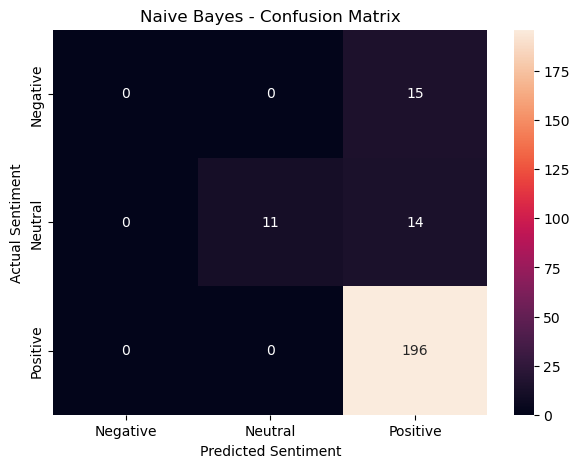

In [67]:
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=['Negative', 'Neutral', 'Positive']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [68]:
nb_results = {
    'Model': 'Naive Bayes',
    'Accuracy': accuracy_nb,
    'Precision': precision_nb,
    'Recall': recall_nb,
    'F1 Score': f1_nb
}

print(nb_results)

{'Model': 'Naive Bayes', 'Accuracy': 0.8771186440677966, 'Precision': 0.8293973634651601, 'Recall': 0.8771186440677966, 'F1 Score': 0.838036398853058}


In [69]:
from sklearn.linear_model import LogisticRegression

In [70]:
lr_model = LogisticRegression(
    max_iter=1000
)

lr_model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [71]:
y_pred_lr = lr_model.predict(X_test_tfidf)

In [72]:
print("Actual:", y_test.values[:10])
print("Predicted:", y_pred_lr[:10])

Actual: ['Positive' 'Positive' 'Positive' 'Neutral' 'Negative' 'Negative'
 'Neutral' 'Positive' 'Positive' 'Positive']
Predicted: ['Positive' 'Positive' 'Positive' 'Neutral' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive']


In [73]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

recall_lr = recall_score(
    y_test,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

f1_lr = f1_score(
    y_test,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

print("Logistic Regression Results")
print("----------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1 Score :", f1_lr)

Logistic Regression Results
----------------------------
Accuracy : 0.8813559322033898
Precision: 0.8961864406779662
Recall   : 0.8813559322033898
F1 Score : 0.847822504708098


In [74]:
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       1.00      0.07      0.12        15
     Neutral       1.00      0.44      0.61        25
    Positive       0.88      1.00      0.93       196

    accuracy                           0.88       236
   macro avg       0.96      0.50      0.56       236
weighted avg       0.90      0.88      0.85       236



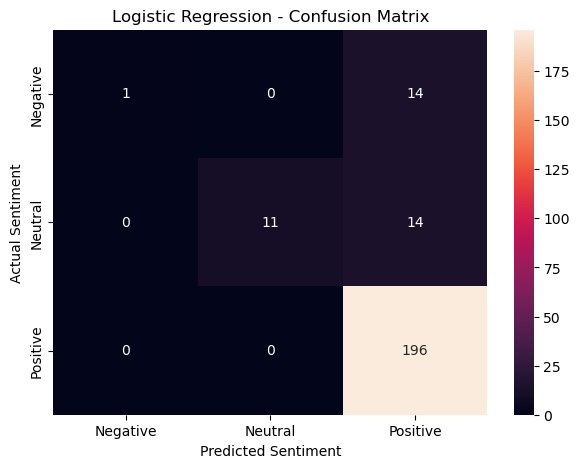

In [75]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=['Negative', 'Neutral', 'Positive']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [76]:
lr_results = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'F1 Score': f1_lr
}

print(lr_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.8813559322033898, 'Precision': 0.8961864406779662, 'Recall': 0.8813559322033898, 'F1 Score': 0.847822504708098}


In [77]:
results_df = pd.DataFrame([
    nb_results,
    lr_results
])

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.877119,0.829397,0.877119,0.838036
1,Logistic Regression,0.881356,0.896186,0.881356,0.847823


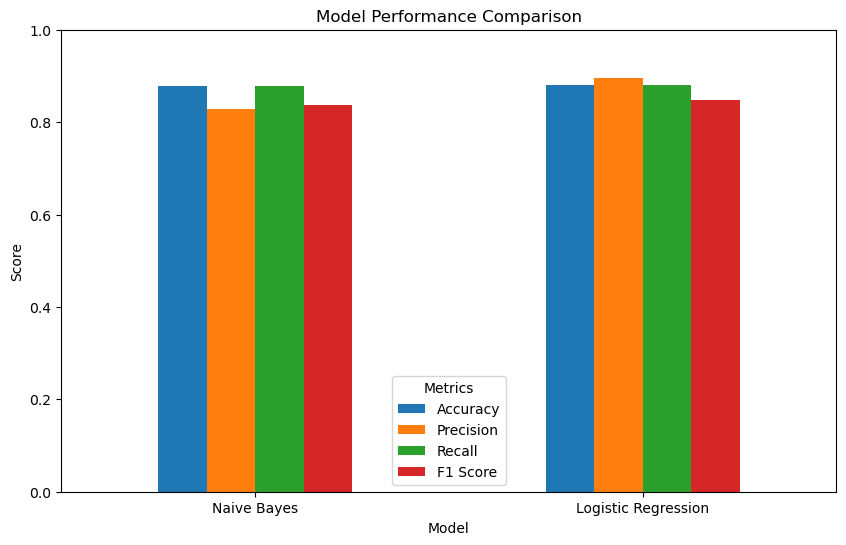

In [78]:
results_plot = results_df.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title='Metrics')

plt.show()

In [79]:
## Model Performance Comparison

In [80]:
#The performance of Multinomial Naive Bayes and Logistic Regression was evaluated
#using accuracy, precision, recall, and F1-score. Since the dataset is highly
#imbalanced, F1-score and class-wise performance are also considered when
#interpreting the models.

In [81]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.877119,0.829397,0.877119,0.838036
1,Logistic Regression,0.881356,0.896186,0.881356,0.847823


In [82]:
from wordcloud import WordCloud

In [83]:
positive_text = ' '.join(
    sentiment_df[sentiment_df['Sentiment'] == 'Positive']['cleaned_text']
)

neutral_text = ' '.join(
    sentiment_df[sentiment_df['Sentiment'] == 'Neutral']['cleaned_text']
)

negative_text = ' '.join(
    sentiment_df[sentiment_df['Sentiment'] == 'Negative']['cleaned_text']
)

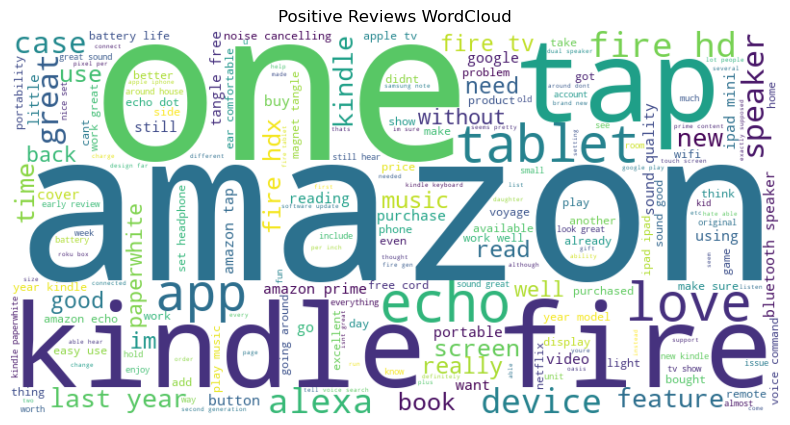

In [84]:
wordcloud_positive = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Reviews WordCloud')
plt.show()

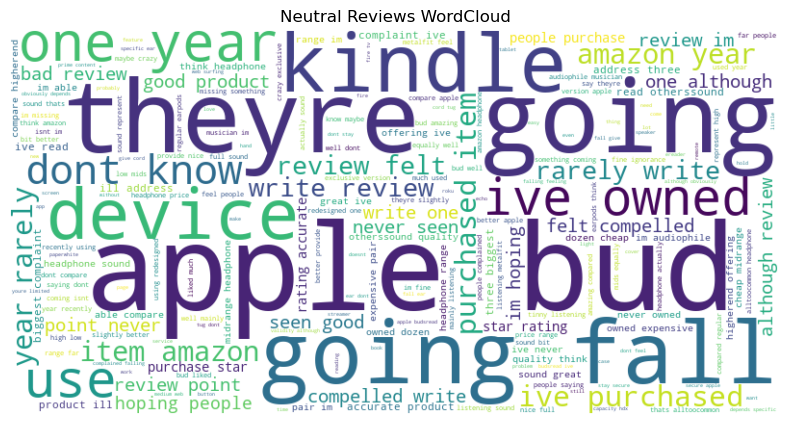

In [85]:
wordcloud_neutral = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(neutral_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_neutral, interpolation='bilinear')
plt.axis('off')
plt.title('Neutral Reviews WordCloud')
plt.show()

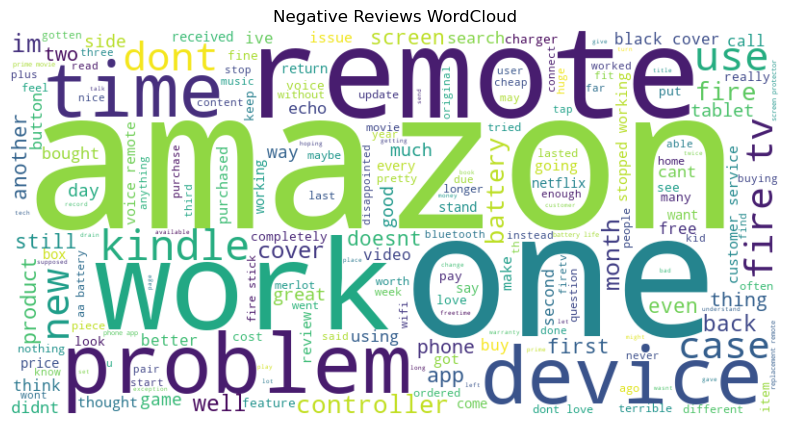

In [86]:
wordcloud_negative = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Reviews WordCloud')
plt.show()

In [87]:
error_df = pd.DataFrame({
    'Review': X_test,
    'Actual': y_test,
    'Predicted': y_pred_lr
})

In [88]:
error_df.head()

,Review,Actual,Predicted
1350,purchased gift teenage kid graduation present ...,Positive,Positive
690,im huge fan echo family two echo three dot one...,Positive,Positive
241,review certified refurbished fire hd unit orde...,Positive,Positive
153,like previous reviewer mentioned fabric hard p...,Neutral,Neutral
1590,voice remote gave nearly year purchased change...,Negative,Positive


In [89]:
misclassified = error_df[
    error_df['Actual'] != error_df['Predicted']
]

In [90]:
print("Number of misclassified reviews:", len(misclassified))

Number of misclassified reviews: 28


In [91]:
misclassified.head(5)

,Review,Actual,Predicted
1590,voice remote gave nearly year purchased change...,Negative,Positive
457,overpriced,Negative,Positive
51,kindle first eink reader ipad iphone owned win...,Neutral,Positive
281,ive got mixed feeling one unfortunately review...,Neutral,Positive
1143,great soundeasy connectproblem voice activated...,Neutral,Positive


In [92]:
for i, row in misclassified.head(5).iterrows():
    print("Review:", row['Review'])
    print("Actual Sentiment:", row['Actual'])
    print("Predicted Sentiment:", row['Predicted'])
    print("-" * 80)

Review: voice remote gave nearly year purchased changed battery several time nothing rely phone app function paid stick promoted prime member want extra might well buy another fire stick rip hollow piece plastic even voice remote feature still dont think worth amazon sell remote dollar prime member shouldnt worry fails outside warranty period amazon already charging arm leg prime membership content begin
Actual Sentiment: Negative
Predicted Sentiment: Positive
--------------------------------------------------------------------------------
Review: overpriced
Actual Sentiment: Negative
Predicted Sentiment: Positive
--------------------------------------------------------------------------------
Review: kindle first eink reader ipad iphone owned windowsbased phone past used ereadermy overall impression device goodthe goodid honestly rather read linear read page one end one page time fiction book cant always get comfortable book hardcover sometimes bit heavy paperback dont always lie open

In [93]:
## Error Analysis

#Five misclassified reviews were examined to understand the limitations of the sentiment classification model.

#The model may misclassify reviews because of ambiguous language, mixed sentiments, sarcasm, limited training examples, and class imbalance.

#The dataset contains significantly more positive reviews than neutral andvnegative reviews. Therefore, the model has fewer examples 
#from which to learn the characteristics of negative and neutral sentiment.

#TF-IDF represents the importance of words and phrases but does not fully understand sentence context, sarcasm, or 
#complex relationships between words.

In [94]:
for i, row in misclassified.head(5).iterrows():
    print("Review:", row['Review'])
    print("Actual:", row['Actual'])
    print("Predicted:", row['Predicted'])
    print("-" * 100)

Review: voice remote gave nearly year purchased changed battery several time nothing rely phone app function paid stick promoted prime member want extra might well buy another fire stick rip hollow piece plastic even voice remote feature still dont think worth amazon sell remote dollar prime member shouldnt worry fails outside warranty period amazon already charging arm leg prime membership content begin
Actual: Negative
Predicted: Positive
----------------------------------------------------------------------------------------------------
Review: overpriced
Actual: Negative
Predicted: Positive
----------------------------------------------------------------------------------------------------
Review: kindle first eink reader ipad iphone owned windowsbased phone past used ereadermy overall impression device goodthe goodid honestly rather read linear read page one end one page time fiction book cant always get comfortable book hardcover sometimes bit heavy paperback dont always lie open

In [95]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.877119,0.829397,0.877119,0.838036
1,Logistic Regression,0.881356,0.896186,0.881356,0.847823


In [96]:
best_f1_model = results_df.loc[
    results_df['F1 Score'].idxmax(), 'Model'
]

print("Model with higher weighted F1-score:", best_f1_model)

Model with higher weighted F1-score: Logistic Regression


In [97]:
best_accuracy_model = results_df.loc[
    results_df['Accuracy'].idxmax(), 'Model'
]

print("Model with higher accuracy:", best_accuracy_model)

Model with higher accuracy: Logistic Regression


In [98]:
## Conclusion

#In this project, sentiment analysis was performed on Amazon product reviews using Natural Language Processing and machine 
#learning techniques.

#The review ratings were converted into three sentiment categories: 
#Negative (ratings 1–2), Neutral (rating 3), and Positive (ratings 4–5).

#The review text was cleaned using lowercase conversion, punctuation removal,tokenization, stopword removal, and lemmatization.
#TF-IDF was then used to convert the text into numerical features.

#Two machine learning classifiers, Multinomial Naive Bayes and Logistic
#Regression, were trained using an 80/20 train-test split. Their performance was
#evaluated using accuracy, precision, recall, F1-score, classification reports,
#and confusion matrices.

#The dataset was highly imbalanced, with positive reviews being much more
#common than neutral and negative reviews. Therefore, accuracy alone was not
#considered sufficient for evaluating model performance.

#Based on the evaluation metrics, the models showed different performance
#characteristics across the three sentiment classes. The class-wise results
#highlight the difficulty of correctly identifying the minority negative and
#neutral reviews.

#The error analysis showed that misclassifications can occur because of
#ambiguous language, mixed opinions, sarcasm, limited training examples, and
#the limitations of TF-IDF in understanding deeper context.

In [ ]:
#The model with the higher weighted F1-score was identified using the evaluation
#results above.

In [99]:
## Real-World Applications

#Sentiment analysis of product reviews can be used in several real-world applications:

#1. Customer Feedback Analysis
 #  Companies can automatically analyze large numbers of customer reviews.

#2. Product Monitoring
 #  Businesses can identify whether customers generally have positive,
  # neutral, or negative opinions about products.

#3. Customer Service
 #  Negative reviews can be identified for further investigation or response.

#4. Brand and Product Reputation
 #  Organizations can monitor customer sentiment over time.

#5. E-commerce Analytics
 #  Sentiment information can be combined with product and sales data to
  # understand customer feedback.

In [100]:
## Project Summary

#Objective:
#Build a machine learning model to classify Amazon product reviews as
#Positive, Negative, or Neutral.

#Dataset:
#Amazon Product Reviews

#Number of usable reviews:
#1,176

#Sentiment Classes:
#Positive, Neutral, Negative

#Text Preprocessing:
#Lowercasing, punctuation removal, tokenization, stopword removal,
#lemmatization

#Feature Extraction:
#TF-IDF

#Train-Test Split:
#80:20

#Machine Learning Models:
#Multinomial Naive Bayes
#Logistic Regression

#Evaluation Metrics:
#Accuracy, Precision, Recall, F1-score, Confusion Matrix

#Visualizations:
#Sentiment Distribution
#WordClouds
#Confusion Matrices
#Model Performance Comparison

#Error Analysis:
#5 misclassified reviews